# App User Behavior Segmentation
## A beginner-friendly project in 10 steps
**Goal:** group users with similar app behavior and suggest actions for each group.

Follow the cells from top to bottom. Each section explains **what**, **why**, and **how**. No advanced pipelines or custom model classes are needed.

**Run in Google Colab:** upload this notebook, then upload `app_user_behavior_dataset.csv` using the Files panel on the left. Select **Runtime > Run all**. Locally, keep the CSV beside the notebook and install the packages listed in `requirements.txt`.

**Important:** the brief describes four clear engagement groups. We test that claim. K-Means can split data even when natural groups are weak. The four labels below are provisional relative labels, not verified customer types. No target label is used for training.

## 1. Data Collection
We use the supplied CSV: one row is one user, and each column describes that user.
The file is already collected; we do not scrape or download another dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from threadpoolctl import threadpool_limits
from IPython.display import display

# Limit CPU threads so the example runs smoothly on smaller computers.
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid")
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)

df = pd.read_csv("app_user_behavior_dataset.csv", dtype={"app_version": "string"})
raw = df.copy()  # Keep an unchanged copy for comparison.
print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (50000, 25)


,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,5,8,8,1,0,20,Basic,9,5,2,NaN,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1,8,24.44,42.03,7,7,3,7,0,0,7,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,5,2,21,1,0,33,Free,11,6,1,2.0,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2,5,3.98,65.38,16,8,4,13,0,0,17,Basic,6,3,1,3.0,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1,10,12.85,57.06,13,7,3,15,0,0,21,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign


## 2. Data Understanding
- `user_id`: identifies a user; it is not a behavior measurement.
- `age`, `gender`, `country`: demographic information.
- `device_type`, `app_version`: device and software details. Version is a category, not a quantity.
- `sessions_per_week`: how often the user opens a session.
- `avg_session_duration_min`, `daily_active_minutes`: duration and daily activity.
- `feature_clicks_per_session`, `pages_viewed_per_session`: interaction depth.
- `notifications_opened_per_week`, `in_app_search_count`: other interactions.
- `crash_events_last_30_days`, `support_tickets_raised`: experience indicators.
- `days_since_last_login`: recency; a larger number means a longer absence.
- `subscription_type`, `marketing_source`: subscription and acquisition categories.
- `ads_clicked_last_30_days`, `content_downloads`, `social_shares`: other activity counts.
- `rating_given`: user rating, from 1 to 5 in this file.
- `engagement_score`, `churn_risk_score`: supplied scores; their formulas are not provided.
- `account_age_days`: time since account creation.

These meanings are inferred from column names. Where no time window is specified, do not invent one. A churn risk score is **not an observed churn outcome**.

In [2]:
df.info()
display(df.describe().round(2))
display(df.describe(include=["object", "string"]))
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate user IDs:", df["user_id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_id                        50000 non-null  int64  
 1   age                            50000 non-null  int64  
 2   gender                         50000 non-null  object 
 3   country                        50000 non-null  object 
 4   device_type                    50000 non-null  object 
 5   app_version                    50000 non-null  string 
 6   sessions_per_week              50000 non-null  int64  
 7   avg_session_duration_min       50000 non-null  float64
 8   daily_active_minutes           50000 non-null  float64
 9   feature_clicks_per_session     50000 non-null  int64  
 10  notifications_opened_per_week  50000 non-null  int64  
 11  in_app_search_count            50000 non-null  int64  
 12  pages_viewed_per_session       50000 non-null 

,user_id,age,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.0,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,44978.00,50000.00,50000.00,50000.00
mean,124999.50,38.51,8.00,13.15,45.16,12.01,5.00,4.0,13.47,0.40,0.20,22.04,6.00,3.00,2.00,3.63,0.50,64.94,603.79
std,14433.90,12.09,2.83,8.95,19.51,3.48,2.24,2.0,6.34,0.63,0.44,12.99,2.45,1.73,1.41,1.09,0.29,14.84,345.57
min,100000.00,18.00,0.00,0.06,5.00,1.00,0.00,0.0,3.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,10.00,7.00
25%,112499.75,28.00,6.00,6.57,31.65,10.00,3.00,3.0,8.00,0.00,0.00,11.00,4.00,2.00,1.00,3.00,0.25,54.90,302.00
50%,124999.50,39.00,8.00,11.24,45.21,12.00,5.00,4.0,13.00,0.00,0.00,22.00,6.00,3.00,2.00,4.00,0.50,65.03,604.00
75%,137499.25,49.00,10.00,17.57,58.44,14.00,6.00,5.0,19.00,1.00,0.00,33.00,8.00,4.00,3.00,4.00,0.75,75.09,906.00
max,149999.00,59.00,26.00,91.40,129.13,28.00,16.00,19.0,24.00,5.00,4.00,44.00,19.00,13.00,11.00,5.00,1.00,100.00,1199.00


,gender,country,device_type,app_version,subscription_type,marketing_source
count,50000,50000,50000,50000,50000,50000
unique,3,7,3,5,3,5
top,Female,India,Android,1,Free,Organic
freq,23994,22550,27315,10158,30088,17539


,missing_values
user_id,0
age,0
gender,0
country,0
device_type,0
app_version,0
sessions_per_week,0
avg_session_duration_min,0
daily_active_minutes,0
feature_clicks_per_session,0


## 3. Data Cleaning
1. Remove exact duplicate rows, if any.
2. Remove unwanted spaces from category values.
3. Flag impossible negative counts/durations and out-of-range scores as missing.
4. Fill missing numeric values with the **median** (middle value), and categories with the **mode** (most common value).

Only `rating_given` is missing in the supplied file: 5,022 rows. We preserve a missing-rating flag so a filled rating is never mistaken for a rating the user actually gave. Ratings are not used for clustering.

We inspect outliers but retain plausible heavy users: an unusually long session is not automatically an error. User IDs must remain unique; conflicting duplicate IDs need investigation rather than averaging.

In [3]:
df = df.drop_duplicates().copy()
assert df["user_id"].notna().all(), "Investigate missing user IDs."
assert df["user_id"].is_unique, "Investigate duplicate user IDs."

category_cols = ["gender", "country", "device_type", "app_version",
                 "subscription_type", "marketing_source"]
for col in category_cols:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)
    df[col] = df[col].fillna(df[col].mode()[0])

numeric_cols = df.select_dtypes(include="number").columns.drop("user_id")
invalid_counts = {}
for col in numeric_cols:
    invalid = (df[col] < 0) | (~np.isfinite(df[col]) & df[col].notna())
    if col == "rating_given":
        invalid = invalid | (df[col] < 1) | (df[col] > 5)
    elif col == "churn_risk_score":
        invalid = invalid | (df[col] > 1)
    elif col == "engagement_score":
        invalid = invalid | (df[col] > 100)
    invalid_counts[col] = int(invalid.sum())
    df.loc[invalid, col] = np.nan

# Save missingness before imputation.
df["rating_was_missing"] = df["rating_given"].isna()
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Invalid numeric values found:", sum(invalid_counts.values()))
print("Ratings imputed:", df["rating_was_missing"].sum())
print("Missing values after cleaning:", df.isna().sum().sum())
assert df.isna().sum().sum() == 0

# IQR flags identify unusual values; they are not automatic deletion rules.
outlier_rows = []
for col in ["sessions_per_week", "avg_session_duration_min", "daily_active_minutes"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    flags = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    outlier_rows.append({"feature": col, "IQR_flagged_rows": int(flags.sum())})
display(pd.DataFrame(outlier_rows))

Invalid numeric values found: 0
Ratings imputed: 5022
Missing values after cleaning: 0


,feature,IQR_flagged_rows
0,sessions_per_week,181
1,avg_session_duration_min,1572
2,daily_active_minutes,181


### Exploratory Data Analysis (EDA)
Histograms show typical values and unusual values. The correlation chart shows whether selected measurements move together. Correlation does not establish cause and effect.

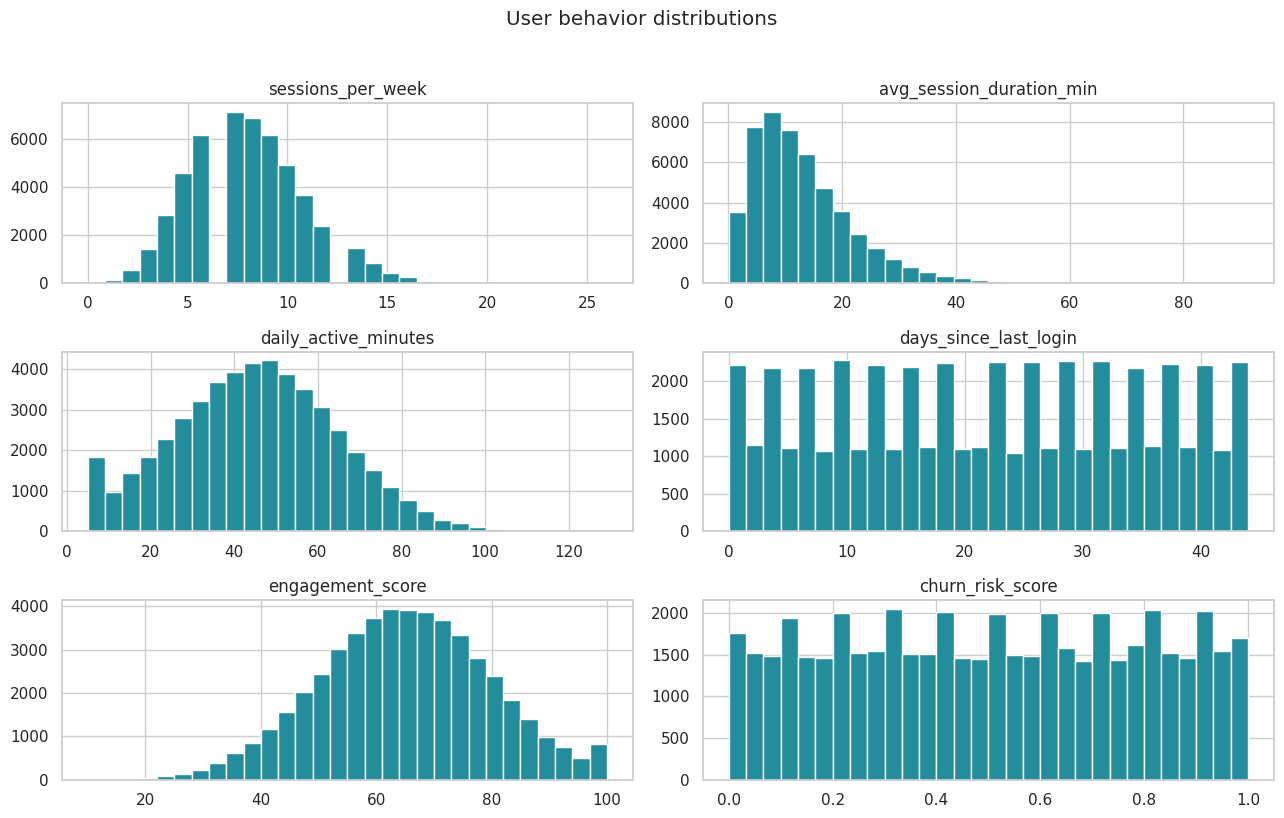

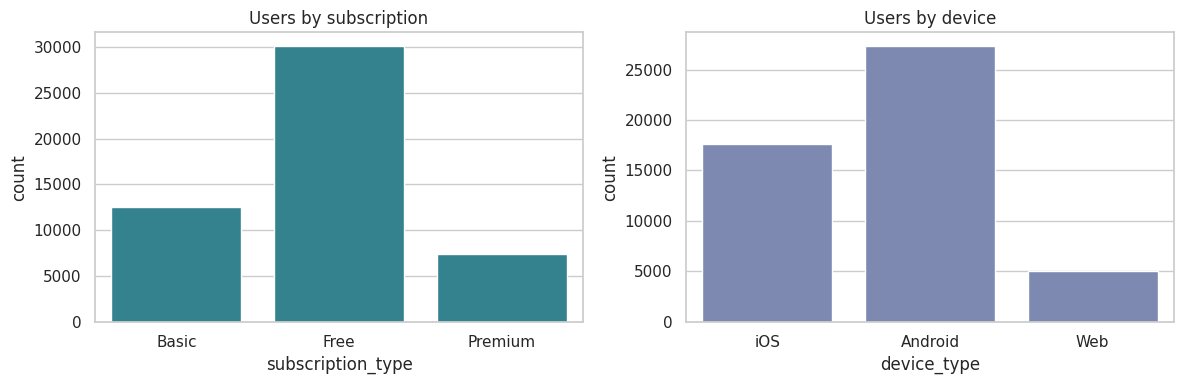

In [4]:
eda_cols = ["sessions_per_week", "avg_session_duration_min", "daily_active_minutes",
            "days_since_last_login", "engagement_score", "churn_risk_score"]
df[eda_cols].hist(figsize=(13, 8), bins=30, color="#248d9d", edgecolor="white")
plt.suptitle("User behavior distributions", y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT / "01_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="subscription_type", ax=axes[0], color="#248d9d")
sns.countplot(data=df, x="device_type", ax=axes[1], color="#7484b9")
axes[0].set_title("Users by subscription")
axes[1].set_title("Users by device")
plt.tight_layout()
plt.savefig(OUTPUT / "02_categories.png", dpi=150)
plt.show()

## 4. Feature Selection
We choose seven numeric features covering frequency, duration, daily activity, interaction depth, recency, and the supplied engagement score.

**Excluded:** user ID (identifier), demographics/categories (keep the first model focused on behavior), rating (missing for many users), churn risk (profile it after clustering), and redundant extra interaction counts (keep the model simple).

The engagement score's formula is unknown. It may partly repeat other inputs. This is a baseline choice; a future comparison should exclude it and check whether the conclusions change. We do not claim that these are uniquely optimal features.

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,pages_viewed_per_session,days_since_last_login,engagement_score
0,5.0,3.41,52.71,13.0,8.0,20.0,55.79
1,8.0,24.44,42.03,7.0,7.0,7.0,82.39
2,12.0,5.34,76.69,7.0,21.0,33.0,42.49
3,5.0,3.98,65.38,16.0,13.0,17.0,62.81
4,10.0,12.85,57.06,13.0,15.0,21.0,38.21


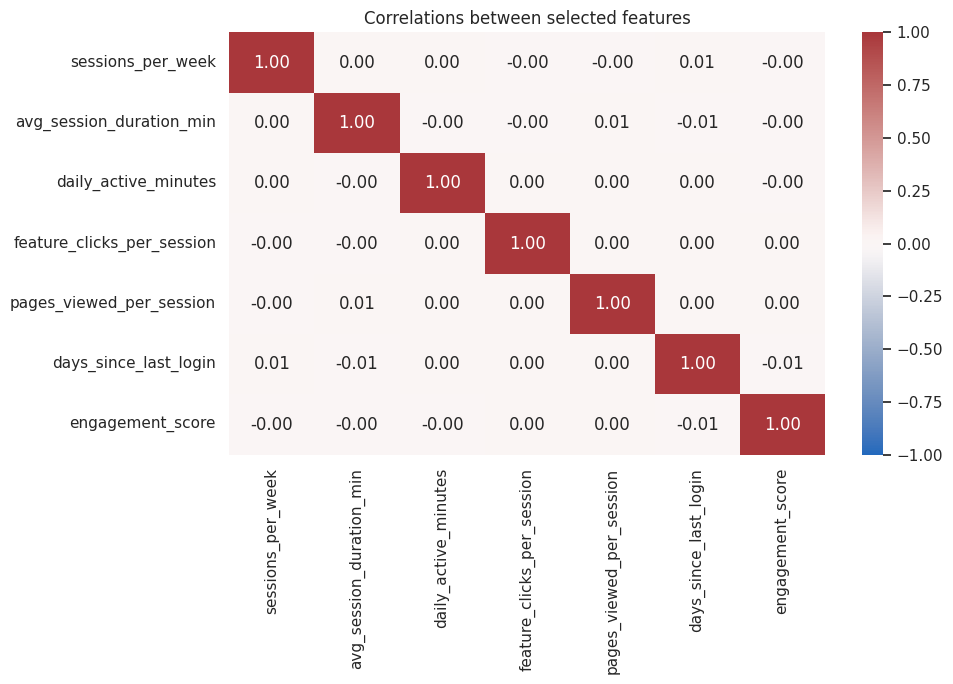

In [5]:
features = [
    "sessions_per_week",
    "avg_session_duration_min",
    "daily_active_minutes",
    "feature_clicks_per_session",
    "pages_viewed_per_session",
    "days_since_last_login",
    "engagement_score"
]
X = df[features].copy()
display(X.head())
plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlations between selected features")
plt.tight_layout()
plt.savefig(OUTPUT / "03_correlations.png", dpi=150)
plt.show()

## 5. Data Scaling
**StandardScaler:** scaled value = (original value - mean) / standard deviation.

Example: a feature measured in minutes may have larger numbers than a count. Scaling makes feature variances comparable so the larger numerical unit does not dominate distances. It does not guarantee equal business importance, and it does not turn every distribution into a normal distribution.

We fit on all users because the task is descriptive segmentation of this snapshot. A future-user evaluation would fit preprocessing only on its training data.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
scaled_df = pd.DataFrame(X_scaled, columns=features, index=df.index)
display(scaled_df.head().round(2))
display(pd.DataFrame({"mean_after_scaling": X_scaled.mean(axis=0),
                      "std_after_scaling": X_scaled.std(axis=0)}, index=features).round(3))

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,pages_viewed_per_session,days_since_last_login,engagement_score
0,-1.06,-1.09,0.39,0.28,-0.86,-0.16,-0.62
1,0.00,1.26,-0.16,-1.44,-1.02,-1.16,1.18
2,1.41,-0.87,1.62,-1.44,1.19,0.84,-1.51
3,-1.06,-1.02,1.04,1.15,-0.07,-0.39,-0.14
4,0.71,-0.03,0.61,0.28,0.24,-0.08,-1.80


,mean_after_scaling,std_after_scaling
sessions_per_week,0.0,1.0
avg_session_duration_min,-0.0,1.0
daily_active_minutes,-0.0,1.0
feature_clicks_per_session,-0.0,1.0
pages_viewed_per_session,-0.0,1.0
days_since_last_login,0.0,1.0
engagement_score,0.0,1.0


## 6. Clustering Model Selection
**K-Means** places K centers in the data and assigns each user to the closest center. It then updates the centers until assignments stabilize.

- `n_clusters`: number of groups.
- `random_state=42`: makes the run repeatable in the same software environment.
- `n_init=10`: tries ten starting arrangements and keeps the best one.

Cluster numbers are identifiers, not rankings. Cluster 0 does not automatically mean high engagement.

## 7. Optimal Cluster Identification
The **elbow plot** compares K with inertia (within-group squared distance). Look for a bend after which adding groups gives only small improvements. Inertia always decreases as K increases, so the smallest inertia alone cannot choose K.

We also calculate **silhouette score** on a fixed random sample of 3,000 users to keep computation manageable. It ranges from -1 to 1; higher is better, and values near zero suggest overlap. It is not prediction accuracy.

We examine K=1 to 10. A smooth curve without a clear bend means we should not claim a definite optimum.

Best sampled silhouette K: 2


,k,inertia,silhouette,inertia_reduction_pct
0,1,350000.0000,NaN,NaN
1,2,312411.1337,0.1127,10.7397
2,3,287438.3147,0.1114,7.9936
3,4,267870.2618,0.1035,6.8077
4,5,252650.7346,0.1026,5.6817
5,6,239635.7125,0.1040,5.1514
6,7,228429.8588,0.1066,4.6762
7,8,219005.0556,0.1054,4.1259
8,9,211920.5593,0.1032,3.2349
9,10,205356.1486,0.1028,3.0976


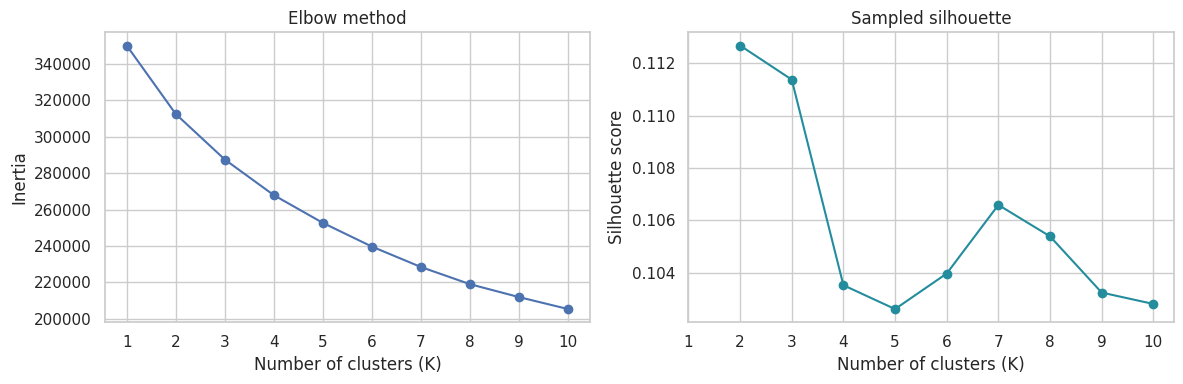

In [7]:
evaluation = []
for k in range(1, 11):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    candidate_labels = candidate.fit_predict(X_scaled)
    score = np.nan
    if k >= 2:
        score = silhouette_score(X_scaled, candidate_labels,
                                 sample_size=3000, random_state=42)
    evaluation.append({"k": k, "inertia": candidate.inertia_, "silhouette": score})

metrics = pd.DataFrame(evaluation)
metrics["inertia_reduction_pct"] = -metrics["inertia"].pct_change() * 100
display(metrics.round(4))
metrics.to_csv(OUTPUT / "cluster_evaluation.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metrics["k"], metrics["inertia"], "o-")
axes[0].set(title="Elbow method", xlabel="Number of clusters (K)", ylabel="Inertia")
axes[1].plot(metrics["k"], metrics["silhouette"], "o-", color="#248d9d")
axes[1].set(title="Sampled silhouette", xlabel="Number of clusters (K)", ylabel="Silhouette score")
for ax in axes:
    ax.set_xticks(range(1, 11))
plt.tight_layout()
plt.savefig(OUTPUT / "04_choose_k.png", dpi=150)
plt.show()
print("Best sampled silhouette K:", int(metrics.loc[metrics["silhouette"].idxmax(), "k"]))

### Decision for this project
The supplied dataset shows weak separation and no compelling elbow. K=2 has the highest sampled silhouette among the tested values, but even that score is low.

We use **K=4 as the requested business/project configuration**, not as a proven statistical optimum. This preserves the four-group exercise while honestly reporting its limitations. A defensible project conclusion may be that better behavior data is needed.

## 8. Cluster Assignment
Fit the four-cluster model and attach each user's cluster number. Evaluate separation in the full seven-feature space; use PCA only for a two-dimensional view.

Four-cluster silhouette: 0.1035
Davies-Bouldin score (lower is better): 2.2004
Variance retained in the 2D view: 28.86 %


,user_id,cluster
0,100000,1
1,100001,2
2,100002,0
3,100003,3
4,100004,0
5,100005,3
6,100006,1
7,100007,1
8,100008,2
9,100009,2


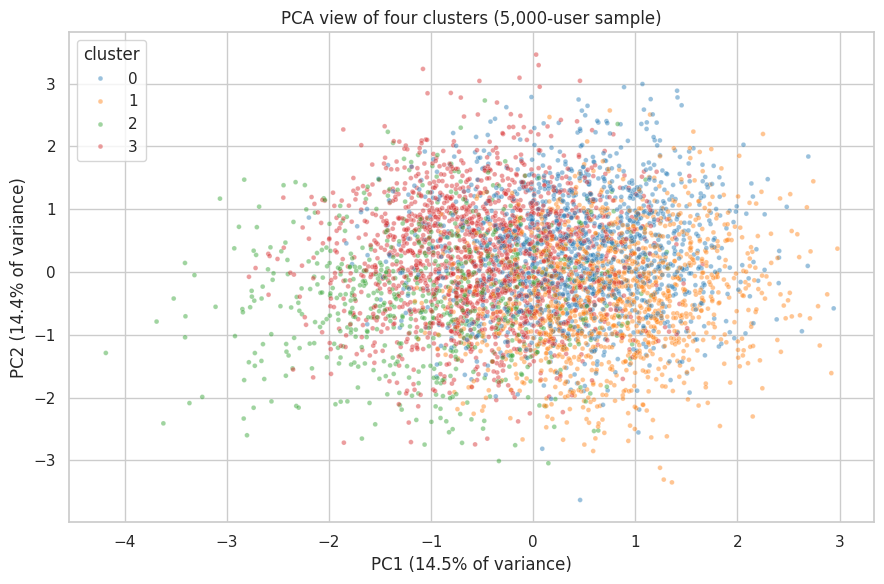

In [8]:
CHOSEN_K = 4
model = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
df["cluster"] = model.fit_predict(X_scaled)
final_silhouette = silhouette_score(X_scaled, df["cluster"], sample_size=3000, random_state=42)
db_score = davies_bouldin_score(X_scaled, df["cluster"])
print("Four-cluster silhouette:", round(final_silhouette, 4))
print("Davies-Bouldin score (lower is better):", round(db_score, 4))
display(df[["user_id", "cluster"]].head(10))

pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame(coordinates, columns=["PC1", "PC2"])
plot_df["cluster"] = df["cluster"].to_numpy()
plot_sample = plot_df.sample(n=min(5000, len(plot_df)), random_state=42)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_sample, x="PC1", y="PC2", hue="cluster",
                palette="tab10", s=12, alpha=0.45)
plt.title("PCA view of four clusters (5,000-user sample)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.tight_layout()
plt.savefig(OUTPUT / "05_pca_clusters.png", dpi=150)
plt.show()
print("Variance retained in the 2D view:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

**Reading PCA:** each dot represents a user. PCA compresses seven measurements into two axes, so some information is lost. Colored regions alone do not validate meaningful clusters. In this dataset, the low silhouette is evidence that the groups overlap.

## 9. Cluster-Level User Identification and Profiling
First compare actual averages. Next attach the requested names using a transparent, provisional ranking:

**Relative activity index** = average of standardized session frequency, daily minutes, engagement score, and reversed days since login. Larger means relatively more active/recent. This index names the clusters after fitting; it does not train K-Means.

Rank cluster-average activity from highest to lowest and assign **High, Moderate, Occasional, Low / At-Risk**. These are project labels only. In particular, “Occasional” is a lower-middle label, not proof of irregular visits; “At-Risk” is not a churn prediction. All groups may have similar engagement or churn averages.

We retain user IDs so you can extract the exact users in each group.

Cluster 0: Occasional - 13,332 users
Cluster 1: Low Engagement / At-Risk - 13,404 users
Cluster 2: Moderate Engagement - 7,101 users
Cluster 3: High Engagement - 16,163 users


,user_count,percent_users,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,pages_viewed_per_session,days_since_last_login,engagement_score,churn_risk_score,account_age_days,segment,relative_activity_index,observed_pattern
cluster,,,,,,,,,,,,,,
0,13332,26.664,8.066,10.416,45.348,12.050,19.485,30.599,64.822,0.500,602.113,Occasional,-0.159,Less recent logins; more pages per session
1,13404,26.808,8.097,10.570,45.132,12.025,7.513,30.686,64.548,0.498,604.903,Low Engagement / At-Risk,-0.165,Less recent logins; fewer pages per session
2,7101,14.202,8.073,29.665,44.905,11.974,13.758,21.004,65.149,0.498,604.508,Moderate Engagement,0.027,Longer sessions
3,16163,32.326,7.833,10.289,45.155,11.992,13.324,8.260,65.272,0.505,603.919,High Engagement,0.256,More recent logins


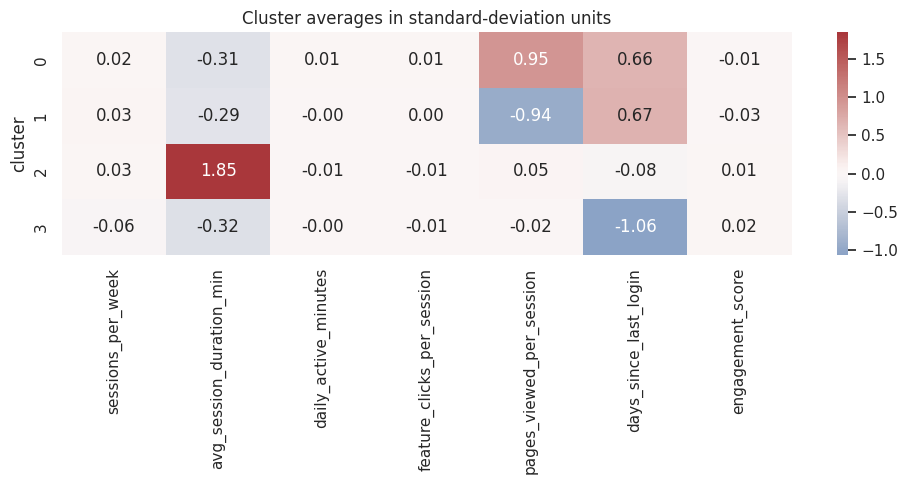

,user_id,segment,engagement_score,churn_risk_score
2,100002,Occasional,42.49,0.63
4,100004,Occasional,38.21,0.43
10,100010,Occasional,56.02,0.38
13,100013,Occasional,67.25,0.48
19,100019,Occasional,68.99,0.84


,user_id,segment,engagement_score,churn_risk_score
0,100000,Low Engagement / At-Risk,55.79,0.31
6,100006,Low Engagement / At-Risk,63.30,0.78
7,100007,Low Engagement / At-Risk,84.81,0.51
11,100011,Low Engagement / At-Risk,74.70,0.32
16,100016,Low Engagement / At-Risk,73.52,0.25


,user_id,segment,engagement_score,churn_risk_score
1,100001,Moderate Engagement,82.39,0.87
8,100008,Moderate Engagement,72.85,0.08
9,100009,Moderate Engagement,55.92,0.19
15,100015,Moderate Engagement,52.69,0.26
36,100036,Moderate Engagement,71.31,0.43


,user_id,segment,engagement_score,churn_risk_score
3,100003,High Engagement,62.81,0.43
5,100005,High Engagement,91.45,0.65
12,100012,High Engagement,62.19,0.07
14,100014,High Engagement,51.33,0.98
17,100017,High Engagement,100.00,0.21


In [9]:
profile_cols = features + ["churn_risk_score", "account_age_days"]
profile = df.groupby("cluster")[profile_cols].mean()
profile.insert(0, "user_count", df.groupby("cluster").size())
profile.insert(1, "percent_users", profile["user_count"] / len(df) * 100)

activity_index = (scaled_df["sessions_per_week"] + scaled_df["daily_active_minutes"]
                  + scaled_df["engagement_score"] - scaled_df["days_since_last_login"]) / 4
df["relative_activity_index"] = activity_index
ranked_clusters = df.groupby("cluster")["relative_activity_index"].mean().sort_values(ascending=False).index
requested_names = ["High Engagement", "Moderate Engagement", "Occasional", "Low Engagement / At-Risk"]
segment_names = dict(zip(ranked_clusters, requested_names))
df["segment"] = df["cluster"].map(segment_names)
profile["segment"] = profile.index.map(segment_names)
profile["relative_activity_index"] = df.groupby("cluster")["relative_activity_index"].mean()

# Describe actual behaviors separately from the requested names.
long_sessions = profile["avg_session_duration_min"].idxmax()
remaining = profile.drop(index=long_sessions)
recent_users = remaining["days_since_last_login"].idxmin()
remaining = remaining.drop(index=recent_users)
more_pages = remaining["pages_viewed_per_session"].idxmax()
fewer_pages = remaining["pages_viewed_per_session"].idxmin()
behavior_names = {
    long_sessions: "Longer sessions",
    recent_users: "More recent logins",
    more_pages: "Less recent logins; more pages per session",
    fewer_pages: "Less recent logins; fewer pages per session"
}
profile["observed_pattern"] = profile.index.map(behavior_names)
df["observed_pattern"] = df["cluster"].map(behavior_names)
display(profile.round(3))

plt.figure(figsize=(10, 5))
sns.heatmap(scaled_df.groupby(df["cluster"]).mean(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Cluster averages in standard-deviation units")
plt.tight_layout()
plt.savefig(OUTPUT / "06_cluster_profiles.png", dpi=150)
plt.show()

for cluster_id in range(CHOSEN_K):
    users = df[df["cluster"] == cluster_id]
    print(f"Cluster {cluster_id}: {segment_names[cluster_id]} - {len(users):,} users")
    display(users[["user_id", "segment", "engagement_score", "churn_risk_score"]].head(5))

## 10. Business Insight Generation and Customer Action Mapping
Cluster labels should guide **experiments**, not automatic conclusions.

- Relatively high activity: test loyalty or premium offers with eligible users.
- Moderate activity: test relevant feature tips and personalized content.
- Occasional label: test gentle re-engagement; visit histories are needed to prove irregularity.
- Low / At-Risk label: investigate barriers and test onboarding or reminders.

Use individual flags as well as clusters. The following thresholds are **illustrative business rules**, not learned or validated risk cutoffs:
- Retention review: supplied churn score >= 0.70, OR engagement < 50 and no login for >= 30 days.
- Loyalty review: engagement >= 80 and sessions >= 10 per week.

Revenue is not supplied, so we identify engaged candidates, not proven high-value customers. Retention takes priority if both rules match. Review score definitions and notification consent before real campaigns.

In [10]:
actions = {
    "High Engagement": "Test loyalty or premium offer",
    "Moderate Engagement": "Test personalized content and feature tips",
    "Occasional": "Test gentle re-engagement reminder",
    "Low Engagement / At-Risk": "Investigate barriers; test onboarding support"
}
df["cluster_action"] = df["segment"].map(actions)
df["retention_review_flag"] = (df["churn_risk_score"] >= 0.70) | (
    (df["engagement_score"] < 50) & (df["days_since_last_login"] >= 30))
df["loyalty_candidate_flag"] = (df["engagement_score"] >= 80) & (df["sessions_per_week"] >= 10)
df["recommended_action"] = df["cluster_action"]
df.loc[df["loyalty_candidate_flag"], "recommended_action"] = "Review eligibility for loyalty or premium offer"
df.loc[df["retention_review_flag"], "recommended_action"] = "Review retention need before any promotion"

profile["retention_review_users"] = df.groupby("cluster")["retention_review_flag"].sum()
profile["loyalty_candidates"] = df.groupby("cluster")["loyalty_candidate_flag"].sum()
profile["suggested_cluster_action"] = profile["segment"].map(actions)
display(profile[["segment", "observed_pattern", "user_count", "engagement_score",
                 "churn_risk_score", "retention_review_users", "loyalty_candidates"]].round(2))
display(df[["user_id", "segment", "observed_pattern", "engagement_score", "churn_risk_score",
            "retention_review_flag", "loyalty_candidate_flag", "recommended_action"]].head(10))

# Export all users with original attributes, segment, flags, and suggested action.
df.to_csv(OUTPUT / "users_with_segments.csv", index=False)
profile.to_csv(OUTPUT / "cluster_summary.csv")
for cluster_id in range(CHOSEN_K):
    df[df["cluster"] == cluster_id].to_csv(OUTPUT / f"cluster_{cluster_id}_users.csv", index=False)
df[df["retention_review_flag"]].to_csv(OUTPUT / "retention_review_users.csv", index=False)
df[df["loyalty_candidate_flag"] & ~df["retention_review_flag"]].to_csv(
    OUTPUT / "loyalty_review_users.csv", index=False)

assert len(df) == 50000
assert df["user_id"].is_unique
assert profile["user_count"].sum() == len(df)
assert df["cluster"].nunique() == CHOSEN_K
assert df["segment"].notna().all()
print("Validation passed. Results saved in:", OUTPUT.resolve())

Validation passed. Results saved in: /workspace/scratch/be2f11cd43c8/project/outputs


,segment,observed_pattern,user_count,engagement_score,churn_risk_score,retention_review_users,loyalty_candidates
cluster,,,,,,,
0,Occasional,Less recent logins; more pages per session,13332,64.82,0.50,4895,603
1,Low Engagement / At-Risk,Less recent logins; fewer pages per session,13404,64.55,0.50,4869,573
2,Moderate Engagement,Longer sessions,7101,65.15,0.50,2401,352
3,High Engagement,More recent logins,16163,65.27,0.51,5064,682


,user_id,segment,observed_pattern,engagement_score,churn_risk_score,retention_review_flag,loyalty_candidate_flag,recommended_action
0,100000,Low Engagement / At-Risk,Less recent logins; fewer pages per session,55.79,0.31,False,False,Investigate barriers; test onboarding support
1,100001,Moderate Engagement,Longer sessions,82.39,0.87,True,False,Review retention need before any promotion
2,100002,Occasional,Less recent logins; more pages per session,42.49,0.63,True,False,Review retention need before any promotion
3,100003,High Engagement,More recent logins,62.81,0.43,False,False,Test loyalty or premium offer
4,100004,Occasional,Less recent logins; more pages per session,38.21,0.43,False,False,Test gentle re-engagement reminder
5,100005,High Engagement,More recent logins,91.45,0.65,False,True,Review eligibility for loyalty or premium offer
6,100006,Low Engagement / At-Risk,Less recent logins; fewer pages per session,63.30,0.78,True,False,Review retention need before any promotion
7,100007,Low Engagement / At-Risk,Less recent logins; fewer pages per session,84.81,0.51,False,False,Investigate barriers; test onboarding support
8,100008,Moderate Engagement,Longer sessions,72.85,0.08,False,False,Test personalized content and feature tips
9,100009,Moderate Engagement,Longer sessions,55.92,0.19,False,False,Test personalized content and feature tips


## Conclusion and honest project explanation
We cleaned 50,000 users, selected seven behavior features, standardized them, compared cluster counts, fitted K-Means, visualized PCA, and exported user-level segments with action suggestions.

The four-cluster sampled silhouette is approximately **0.104**, indicating substantial overlap. The groups differ more in session duration, page views, and login recency than in average engagement or supplied churn risk. Thus, this dataset does **not** support the brief's claim of four clearly separated high/moderate/low/occasional behavior types.

K=4 is an assignment/business choice, not a demonstrated optimum. The supplied churn scores are descriptive inputs for review, not calibrated probabilities or actual churn labels. No churn accuracy, revenue uplift, or production readiness has been demonstrated.

**Next steps:** obtain score definitions and dated activity logs, check contradictory time-window measurements with the data owner, compare features with/without engagement score, assess stability across time and random seeds, and test campaigns on small randomized groups. The current snapshot cannot establish causal impact or visit regularity.

### Short viva answers
- **Why unsupervised?** We group users without a known target label.
- **Why scale?** K-Means uses distances; different units can dominate those distances.
- **Why not user ID?** Its number does not measure behavior.
- **Why four clusters?** The requested project uses four; the data does not establish four as optimal.
- **What is inertia?** Total squared distance from each user to its cluster center.
- **What is silhouette?** A separation measure, not classification accuracy.
- **Why PCA?** To view seven features in two dimensions; it is not used for model fitting here.
- **Did we predict churn?** No. We summarized supplied scores and created review flags.
- **Can we call these high-value users?** No. Financial value needs revenue or profitability data.